In [2]:
import pandas as pd
import matplotlib.pyplot as plt
data = pd.read_csv("babies.csv")
data


,Unnamed: 0,id,pluralty,outcome,date,gestation,sex,wt,parity,race,...,drace,dage,ded,dht,dwt,marital,inc,smoke,time,number
0,1,15,5,1,1411,284,1,120.0,1,8,...,8,31,5,65,110,1,1,0,0,0
1,2,20,5,1,1499,282,1,113.0,2,0,...,0,38,5,70,148,1,4,0,0,0
2,3,58,5,1,1576,279,1,128.0,1,0,...,5,32,1,99,999,1,2,1,1,1
3,4,61,5,1,1504,999,1,123.0,2,0,...,3,43,4,68,197,1,8,3,5,5
4,5,72,5,1,1425,282,1,108.0,1,0,...,0,24,5,99,999,1,1,1,1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1231,1232,9153,5,1,1672,275,1,113.0,0,0,...,0,32,4,72,190,1,4,0,0,0
1232,1233,9163,5,1,1712,265,1,128.0,1,0,...,0,24,5,73,170,1,3,0,0,0
1233,1234,9213,5,1,1672,291,1,130.0,4,1,...,2,30,5,70,180,1,3,1,1,2
1234,1235,9229,5,1,1680,281,1,125.0,0,0,...,0,27,5,71,165,1,1,0,0,0


In [2]:
import pandas as pd
import numpy as np
data = pd.read_csv("babies.csv")

# Assuming 'data' is the pandas DataFrame containing the dataset

# Descriptive statistics for 'wt' (continuous variable)
wt_stats = data['wt'].describe()

# Descriptive statistics for 'smoke' (discrete variable)
smoke_count = data['smoke'].value_counts()

# Print the descriptive statistics
print("Descriptive Statistics for 'wt':")
print(wt_stats)

print("\nCount of 'smoke':")
print(smoke_count)


Descriptive Statistics for 'wt':
count    1226.000000
mean      119.619902
std        18.173335
min        55.000000
25%       109.000000
50%       120.000000
75%       131.000000
max       176.000000
Name: wt, dtype: float64

Count of 'smoke':
0    544
1    482
3    101
2     99
9     10
Name: smoke, dtype: int64


In [4]:
import pandas as pd
data = pd.read_csv("babies.csv")
# Assuming 'data' is the pandas DataFrame containing the dataset

# Find the maximum value of 'wt'
max_wt = data['wt'].min()

# Filter the DataFrame to get rows with maximum 'wt' values
max_wt_rows = data[data['wt'] == max_wt]

# Print the rows with maximum 'wt' values
print("Rows with Maximum 'wt' Value:")
print(max_wt_rows)


Rows with Maximum 'wt' Value:
     Unnamed: 0    id  pluralty  outcome  date  gestation  sex    wt  parity  \
978         979  7722         5        1  1563        204    1  55.0      11   

     race  ...  drace  dage  ded  dht  dwt  marital  inc  smoke  time  number  
978     7  ...      7    36    4   74  250        1    6      0     0       0  

[1 rows x 24 columns]


In [15]:
import pandas as pd
import scipy.stats as stats
data = pd.read_csv("babies.csv")

# Assuming 'data' is the pandas DataFrame containing the dataset

# Group the data by category
grouped_data = data.groupby('wt')['dwt']

# Perform the ANOVA test
f_statistic, p_value = stats.f_oneway(*[group for name, group in grouped_data])

# Print the results
print("ANOVA Test Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)


ANOVA Test Results:
F-statistic: 0.9076057499868732
p-value: 0.7341599849743511


In [16]:
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
data = pd.read_csv("babies.csv")

# Assuming you have the birth weight data loaded as a pandas DataFrame called "data"
# and the birth weights are in the column "wt"

# Convert the "pluralty" column to categorical
data['pluralty'] = pd.Categorical(data['pluralty'])

# Perform ANOVA
model = ols('wt ~ pluralty', data=data).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

# Print the ANOVA results
print(anova_table)


ValueError: must have at least one row in constraint matrix

In [17]:
import pandas as pd
import scipy.stats as stats
data = pd.read_csv("babies.csv")
# Assuming you have the birth weight data loaded as a pandas DataFrame called "data"
# and the birth weights are in the column "wt"

# Convert the "pluralty" column to categorical
data['pluralty'] = pd.Categorical(data['pluralty'])

# Perform ANOVA
groups = [group['wt'] for name, group in data.groupby('pluralty')]
f_statistic, p_value = stats.f_oneway(*groups)

# Print the ANOVA results
print("F-Statistic:", f_statistic)
print("p-value:", p_value)


TypeError: at least two inputs are required; got 1.

In [18]:
import pandas as pd
from scipy import stats
data = pd.read_csv("babies.csv")

# Create a DataFrame with the data
data = pd.DataFrame({
    'wt': [1150, 1250, 1350, 1400, 1250, 1300, 1350, 1300, 1450],
    'pluralty': ['Single', 'Single', 'Single', 'Single', 'Single', 'Single', 'Single', 'Single', 'Single']
})

# Group the data by 'pluralty' and collect the weights
groups = [group['wt'] for name, group in data.groupby('pluralty')]

# Perform ANOVA if there are at least two groups
if len(groups) < 2:
    print("ANOVA test cannot be performed as there is only one group.")
else:
    # Perform ANOVA
    f_statistic, p_value = stats.f_oneway(*groups)

    # Print the ANOVA results
    print("F-Statistic:", f_statistic)
    print("p-value:", p_value)


ANOVA test cannot be performed as there is only one group.


In [24]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
data = pd.read_csv("babies.csv")


# Fit the ANOVA model
model = ols('wt ~ race', data=data).fit()

# Perform ANOVA
anova_table = sm.stats.anova_lm(model, typ=2)

# Print the ANOVA results
print(anova_table)

                 sum_sq      df          F    PR(>F)
race        4731.135944     1.0  14.482716  0.000148
Residual  399849.738445  1224.0        NaN       NaN


In [23]:
import pandas as pd
import statsmodels.stats.multicomp as mc
data = pd.read_csv("babies.csv")

# Assuming 'data' is the pandas DataFrame containing the dataset
# and 'birth_weight' and 'category' are the corresponding column names

# Perform the pairwise two-sample tests using Tukey's HSD
tukey_results = mc.MultiComparison(data['wt'], data['race']).tukeyhsd()

# Print the Tukey's HSD results
print("Tukey's HSD Test Results:")
print(tukey_results)

# Calculate the Tukey's confidence intervals
tukey_intervals = tukey_results.confint

# Print the Tukey's confidence intervals
print("\nTukey's Confidence Intervals:")
print(tukey_intervals)


Tukey's HSD Test Results:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj lower upper reject
-----------------------------------------------
     0      1      nan   nan   nan   nan  False
     0      2      nan   nan   nan   nan  False
     0      3      nan   nan   nan   nan  False
     0      4      nan   nan   nan   nan  False
     0      5      nan   nan   nan   nan  False
     0      6      nan   nan   nan   nan  False
     0      7      nan   nan   nan   nan  False
     0      8      nan   nan   nan   nan  False
     0      9      nan   nan   nan   nan  False
     0     10      nan   nan   nan   nan  False
     0     99      nan   nan   nan   nan  False
     1      2      nan   nan   nan   nan  False
     1      3      nan   nan   nan   nan  False
     1      4      nan   nan   nan   nan  False
     1      5      nan   nan   nan   nan  False
     1      6      nan   nan   nan   nan  False
     1      7      nan   nan   nan   nan  False
     1    

In [32]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
data = pd.read_csv("babies.csv")

# Assuming 'data' is the pandas DataFrame containing the dataset
# and 'birth_weight' and 'category' are the corresponding column names

# Perform one-way ANOVA
model = ols('wt ~ race', data=data).fit()
anova_table = sm.stats.anova_lm(model)

# Check if the overall test is significant
if anova_table['PR(>F)'][0] < 0.05:
    # Perform pairwise Tukey's HSD test
    pairwise_results = sm.stats.multicomp.pairwise_tukeyhsd(data['wt'], data['race'])

    # Print the pairwise comparison results
    print("Pairwise Comparison Results:")
    print(pairwise_results.summary())


Pairwise Comparison Results:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj lower upper reject
-----------------------------------------------
     0      1      nan   nan   nan   nan  False
     0      2      nan   nan   nan   nan  False
     0      3      nan   nan   nan   nan  False
     0      4      nan   nan   nan   nan  False
     0      5      nan   nan   nan   nan  False
     0      6      nan   nan   nan   nan  False
     0      7      nan   nan   nan   nan  False
     0      8      nan   nan   nan   nan  False
     0      9      nan   nan   nan   nan  False
     0     10      nan   nan   nan   nan  False
     0     99      nan   nan   nan   nan  False
     1      2      nan   nan   nan   nan  False
     1      3      nan   nan   nan   nan  False
     1      4      nan   nan   nan   nan  False
     1      5      nan   nan   nan   nan  False
     1      6      nan   nan   nan   nan  False
     1      7      nan   nan   nan   nan  False
     1 

In [36]:
import pandas as pd


from scipy import stats
import itertools
data = pd.read_csv("babies.csv")
from scipy import stats

import pandas as pd


bw_data = data['wt']

# Get unique categories from the dataset
categories = bw_data.unique()

# Perform pairwise t-tests
pairwise_results = []
for pair in itertools.combinations(categories, 2):
    group1 = bw_data[bw_data == pair[0]]
    group2 = bw_data[bw_data == pair[1]]
    
    # Check if each group has at least two observations
    if len(group1) >= 2 and len(group2) >= 2:
        t_stat, p_value = stats.ttest_ind(group1, group2)
        pairwise_results.append((pair[0], pair[1], t_stat, p_value))

# Print the pairwise results
for result in pairwise_results:
    group1, group2, t_stat, p_value = result
    print(f"Pair: {group1} vs {group2}")
    print(f"t-statistic: {t_stat}")
    print(f"p-value: {p_value}")
    print(f"---")




Pair: 120.0 vs 113.0
t-statistic: inf
p-value: 0.0
---
Pair: 120.0 vs 128.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 123.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 108.0
t-statistic: inf
p-value: 0.0
---
Pair: 120.0 vs 136.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 138.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 132.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 143.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 140.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 144.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 141.0
t-statistic: -inf
p-value: 0.0
---
Pair: 120.0 vs 110.0
t-statistic: inf
p-value: 0.0
---
Pair: 120.0 vs 114.0
t-statistic: inf
p-value: 0.0
---
Pair: 120.0 vs 115.0
t-statistic: inf
p-value: 0.0
---
Pair: 120.0 vs 92.0
t-statistic: inf
p-value: 0.0
---
Pair: 120.0 vs 119.0
t-statistic: inf
p-value: 0.0
---
Pair: 120.0 vs 105.0
t-statistic: inf
p-value: 0.0
---
Pair: 120.0 vs 137.0
t-statistic: -inf
p-value: 0.0
---
P

---
Pair: 144.0 vs 90.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 98.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 151.0
t-statistic: -inf
p-value: 0.0
---
Pair: 144.0 vs 150.0
t-statistic: -inf
p-value: 0.0
---
Pair: 144.0 vs 154.0
t-statistic: -inf
p-value: 0.0
---
Pair: 144.0 vs 81.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 148.0
t-statistic: -inf
p-value: 0.0
---
Pair: 144.0 vs 80.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 71.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 88.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 163.0
t-statistic: -inf
p-value: 0.0
---
Pair: 144.0 vs 78.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 158.0
t-statistic: -inf
p-value: 0.0
---
Pair: 144.0 vs 174.0
t-statistic: -inf
p-value: 0.0
---
Pair: 144.0 vs 84.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 86.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 77.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.0 vs 72.0
t-statistic: inf
p-value: 0.0
---
Pair: 144.

Pair: 131.0 vs 94.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 109.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 147.0
t-statistic: -inf
p-value: 0.0
---
Pair: 131.0 vs 160.0
t-statistic: -inf
p-value: 0.0
---
Pair: 131.0 vs 96.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 90.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 98.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 151.0
t-statistic: -inf
p-value: 0.0
---
Pair: 131.0 vs 150.0
t-statistic: -inf
p-value: 0.0
---
Pair: 131.0 vs 154.0
t-statistic: -inf
p-value: 0.0
---
Pair: 131.0 vs 81.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 148.0
t-statistic: -inf
p-value: 0.0
---
Pair: 131.0 vs 80.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 71.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 88.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 163.0
t-statistic: -inf
p-value: 0.0
---
Pair: 131.0 vs 78.0
t-statistic: inf
p-value: 0.0
---
Pair: 131.0 vs 158.0
t-statistic: -inf
p-value: 0.0
---
Pair: 131.0

Pair: 145.0 vs 135.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 116.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 126.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 95.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 118.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 100.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 152.0
t-statistic: -inf
p-value: 0.0
---
Pair: 145.0 vs 117.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 112.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 94.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 109.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 147.0
t-statistic: -inf
p-value: 0.0
---
Pair: 145.0 vs 160.0
t-statistic: -inf
p-value: 0.0
---
Pair: 145.0 vs 96.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 90.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 98.0
t-statistic: inf
p-value: 0.0
---
Pair: 145.0 vs 151.0
t-statistic: -inf
p-value: 0.0
---
Pair: 145.0 vs 150.0
t-statistic: -inf
p-value: 0.0
---
Pair: 145.

---
Pair: 95.0 vs 100.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 152.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 117.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 112.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 94.0
t-statistic: inf
p-value: 0.0
---
Pair: 95.0 vs 109.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 147.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 160.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 96.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 90.0
t-statistic: inf
p-value: 0.0
---
Pair: 95.0 vs 98.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 151.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 150.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 154.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 81.0
t-statistic: inf
p-value: 0.0
---
Pair: 95.0 vs 148.0
t-statistic: -inf
p-value: 0.0
---
Pair: 95.0 vs 80.0
t-statistic: inf
p-value: 0.0
---
Pair: 95.0 vs 71.0
t-statistic: inf
p-value: 0.0
---
Pair: 95.0 vs 88.0

In [37]:
import pandas as pd
from scipy import stats
import itertools
data = pd.read_csv("babies.csv")

# Assuming 'data' is the pandas DataFrame containing the dataset
# and 'birth_weight' is the column representing the birth weights

# Create a new DataFrame with the relevant columns
bw_data = data[['group', 'wt']]

# Get unique categories from the 'group' column
categories = bw_data['group'].unique()

# Calculate pairwise differences between means
pairwise_diff = []
for pair in itertools.combinations(categories, 2):
    group1 = bw_data[bw_data['group'] == pair[0]]['wt']
    group2 = bw_data[bw_data['group'] == pair[1]]['wt']
    
    mean_diff = group1.mean() - group2.mean()
    pairwise_diff.append((pair[0], pair[1], mean_diff))

# Print the pairwise differences
for diff in pairwise_diff:
    group1, group2, mean_diff = diff
    print(f"Pair: {group1} vs {group2}")
    print(f"Mean Difference: {mean_diff}")
    print(f"---")


KeyError: "['group'] not in index"

In [4]:

import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Load the dataset from a CSV file
data = pd.read_csv('babies.csv')

# Fit the one-way ANOVA model
model = ols('wt ~ smoke', data=data).fit()

# Perform the ANOVA test
anova_table = sm.stats.anova_lm(model, typ=2)

# Print the ANOVA table
print(anova_table)





                 sum_sq      df         F    PR(>F)
smoke         13.124768     1.0  0.039708  0.842085
Residual  404567.749621  1224.0       NaN       NaN


In [5]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind
from statsmodels.stats.multicomp import pairwise_tukeyhsd
data = pd.read_csv("babies.csv")

# Assuming you have a DataFrame named 'data' with the 'Smoke' and 'wt' columns

# Group the data by the 'Smoke' category
groups = data.groupby('smoke')['wt']

# Extract birth weight values for each category
no_smoke = groups.get_group('No Smoke')
light_smoke = groups.get_group('Light Smoke')
heavy_smoke = groups.get_group('Heavy Smoke')

# Perform pairwise two-sample t-tests
ttest_no_vs_light = ttest_ind(no_smoke, light_smoke)
ttest_no_vs_heavy = ttest_ind(no_smoke, heavy_smoke)
ttest_light_vs_heavy = ttest_ind(light_smoke, heavy_smoke)

# Get the p-values from each t-test
pvalue_no_vs_light = ttest_no_vs_light.pvalue
pvalue_no_vs_heavy = ttest_no_vs_heavy.pvalue
pvalue_light_vs_heavy = ttest_light_vs_heavy.pvalue

# Adjust the p-values using the Bonferroni correction
alpha = 0.05  # Significance level
adjusted_pvalues_bonferroni = [pvalue * 3 for pvalue in [pvalue_no_vs_light, pvalue_no_vs_heavy, pvalue_light_vs_heavy]]

# Perform Tukey's HSD test
data_array = np.concatenate([no_smoke, light_smoke, heavy_smoke])
labels = ['No Smoke'] * len(no_smoke) + ['Light Smoke'] * len(light_smoke) + ['Heavy Smoke'] * len(heavy_smoke)
tukey_results = pairwise_tukeyhsd(data_array, labels, alpha=0.05)

# Print the results
print("Pairwise Two-Sample T-Tests:")
print("No Smoke vs. Light Smoke: p-value =", pvalue_no_vs_light)
print("No Smoke vs. Heavy Smoke: p-value =", pvalue_no_vs_heavy)
print("Light Smoke vs. Heavy Smoke: p-value =", pvalue_light_vs_heavy)

print("\nAdjusted p-values (Bonferroni correction):")
print("No Smoke vs. Light Smoke: p-value =", adjusted_pvalues_bonferroni[0])
print("No Smoke vs. Heavy Smoke: p-value =", adjusted_pvalues_bonferroni[1])
print("Light Smoke vs. Heavy Smoke: p-value =", adjusted_pvalues_bonferroni[2])

print("\nTukey's HSD Test:")
print(tukey_results)



KeyError: 'Smoke'

In [6]:
import pandas as pd
import numpy as np
from itertools import combinations
from scipy.stats import ttest_ind
df = pd.read_csv("babies.csv")

# Assuming you have a DataFrame named 'df' with the 'smoke' and 'wt' columns

# Get unique categories in the 'smoke' column
categories = df['smoke'].unique()

# Generate all pairwise combinations of categories
category_pairs = list(combinations(categories, 2))

# Initialize an empty DataFrame to store the results
output_ttest = pd.DataFrame(columns=['smoke1', 'smoke2', 't_stat', 'p_value', 'smoke1_mean', 'smoke2_mean', 'difference_yes'])

# Perform t-tests for each category pair
for pair in category_pairs:
    category1 = pair[0]
    category2 = pair[1]
    
    # Subset the data for the two categories
    subset = df[(df['smoke'] == category1) | (df['smoke'] == category2)]
    
    # Perform t-test
    t_result = ttest_ind(subset[subset['smoke'] == category1]['wt'],
                         subset[subset['smoke'] == category2]['wt'],
                         equal_var=False)
    
    # Extract the necessary information
    t_statistic = t_result.statistic
    p_value = t_result.pvalue
    smoke1_mean = subset[subset['smoke'] == category1]['wt'].mean()
    smoke2_mean = subset[subset['smoke'] == category2]['wt'].mean()
    difference_yes = p_value < 0.05
    
    # Append the results to the output DataFrame
    output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2,
                                        't_stat': t_statistic, 'p_value': p_value,
                                        'smoke1_mean': smoke1_mean, 'smoke2_mean': smoke2_mean,
                                        'difference_yes': difference_yes},
                                       ignore_index=True)

# Round the numeric columns to 3 decimal places
output_ttest = output_ttest.round({'t_stat': 3, 'p_value': 3, 'smoke1_mean': 3, 'smoke2_mean': 3})

# Print the results
print(output_ttest)


C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\177798894.py:39: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\177798894.py:39: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\177798894.py:39: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\177798894.py:39: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future 

  smoke1 smoke2 t_stat p_value smoke1_mean smoke2_mean difference_yes
0      0      1    NaN     NaN  122.861111  114.108108          False
1      0      3    NaN     NaN  122.861111      124.63          False
2      0      2    NaN     NaN  122.861111  123.084211          False
3      0      9    NaN     NaN  122.861111       126.7          False
4      1      3    NaN     NaN  114.108108      124.63          False
5      1      2    NaN     NaN  114.108108  123.084211          False
6      1      9    NaN     NaN  114.108108       126.7          False
7      3      2    NaN     NaN      124.63  123.084211          False
8      3      9    NaN     NaN      124.63       126.7          False
9      2      9    NaN     NaN  123.084211       126.7          False


C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\177798894.py:39: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\177798894.py:39: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\177798894.py:39: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2,


C:\Users\Parsa\anaconda3\lib\site-packages\pingouin\pairwise.py:28: UserWarning: pairwise_ttests is deprecated, use pairwise_tests instead.
  warnings.warn("pairwise_ttests is deprecated, use pairwise_tests instead.", UserWarning)


KeyError: 'subject'

In [10]:
!pip install pingouin


In [12]:
import pandas as pd
import pingouin as pg
from itertools import combinations
from scipy.stats import ttest_ind
df = pd.read_csv("babies.csv")
# Assuming you have a DataFrame named 'df' with the 'smoke' and 'wt' columns

# Get unique categories in the 'smoke' column
categories = df['smoke'].unique()

# Generate all pairwise combinations of categories
category_pairs = list(combinations(categories, 2))

# Initialize an empty DataFrame to store the results
output_ttest = pd.DataFrame(columns=['smoke1', 'smoke2', 't_stat', 'p_value', 'smoke1_mean', 'smoke2_mean', 'difference_yes'])

# Perform paired t-tests for each category pair
for pair in category_pairs:
    category1 = pair[0]
    category2 = pair[1]
    
    # Subset the data for the two categories
    subset = df[(df['smoke'] == category1) | (df['smoke'] == category2)]
    
    # Perform paired t-test
    t_result = pg.pairwise_ttests(dv='wt', within='smoke', subject='subject', data=subset, padjust='none')
    
    # Extract the necessary information
    t_statistic = t_result['T'].values[0]
    p_value = t_result['p-unc'].values[0]
    smoke1_mean = subset[subset['smoke'] == category1]['wt'].mean()
    smoke2_mean = subset[subset['smoke'] == category2]['wt'].mean()
    difference_yes = p_value < 0.05
    
    # Append the results to the output DataFrame
    output_ttest = pd.concat([output_ttest, pd.DataFrame({'smoke1': [category1], 'smoke2': [category2],
                                                          't_stat': [t_statistic], 'p_value': [p_value],
                                                          'smoke1_mean': [smoke1_mean], 'smoke2_mean': [smoke2_mean],
                                                          'difference_yes': [difference_yes]})],
                             ignore_index=True)

# Round the numeric columns to 3 decimal places
output_ttest = output_ttest.round({'t_stat': 3, 'p_value': 3, 'smoke1_mean': 3, 'smoke2_mean': 3})

# Print the results
print(output_ttest)


C:\Users\Parsa\anaconda3\lib\site-packages\pingouin\pairwise.py:28: UserWarning: pairwise_ttests is deprecated, use pairwise_tests instead.
  warnings.warn("pairwise_ttests is deprecated, use pairwise_tests instead.", UserWarning)


KeyError: 'subject'

In [13]:
import pandas as pd
from itertools import combinations
from scipy.stats import ttest_ind
df = pd.read_csv("babies.csv")

# Create an empty DataFrame to store the results
output_ttest = pd.DataFrame(columns=['smoke1', 'smoke2', 't_stat', 'p_value', 'smoke1_mean', 'smoke2_mean', 'difference_yes'])

# Create all pairwise combinations of smoke categories
smoke_combinations = combinations(df['smoke'].unique(), 2)

# Perform pairwise t-tests
for category1, category2 in smoke_combinations:
    # Subset the data for the two categories
    subset = df[(df['smoke'] == category1) | (df['smoke'] == category2)]
    
    # Perform two-sample t-test
    t_stat, p_value = ttest_ind(subset[subset['smoke'] == category1]['wt'], subset[subset['smoke'] == category2]['wt'])
    
    # Compute means
    smoke1_mean = subset[subset['smoke'] == category1]['wt'].mean()
    smoke2_mean = subset[subset['smoke'] == category2]['wt'].mean()
    
    # Determine if there is a significant difference
    difference_yes = p_value < 0.05
    
    # Append the results to the output DataFrame
    output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
                                        'p_value': p_value, 'smoke1_mean': smoke1_mean,
                                        'smoke2_mean': smoke2_mean, 'difference_yes': difference_yes},
                                       ignore_index=True)

# Print the results
print(output_ttest)


  smoke1 smoke2 t_stat p_value smoke1_mean smoke2_mean difference_yes
0      0      1    NaN     NaN  122.861111  114.108108          False
1      0      3    NaN     NaN  122.861111      124.63          False
2      0      2    NaN     NaN  122.861111  123.084211          False
3      0      9    NaN     NaN  122.861111       126.7          False
4      1      3    NaN     NaN  114.108108      124.63          False
5      1      2    NaN     NaN  114.108108  123.084211          False
6      1      9    NaN     NaN  114.108108       126.7          False
7      3      2    NaN     NaN      124.63  123.084211          False
8      3      9    NaN     NaN      124.63       126.7          False
9      2      9    NaN     NaN  123.084211       126.7          False


C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is d

In [16]:
import pandas as pd
from itertools import combinations
from scipy.stats import ttest_ind
df = pd.read_csv("babies.csv")

# Create an empty DataFrame to store the results
output_ttest = pd.DataFrame(columns=['smoke1', 'smoke2', 't_stat', 'p_value', 'smoke1_mean', 'smoke2_mean', 'difference_yes'])

# Create all pairwise combinations of smoke categories
smoke_combinations = combinations(df['smoke'].unique(), 2)

# Perform pairwise t-tests
for category1, category2 in smoke_combinations:
    # Subset the data for the two categories
    subset = df[(df['smoke'] == category1) | (df['smoke'] == category2)]
    
    # Perform two-sample t-test
    t_stat, p_value = ttest_ind(subset[subset['smoke'] == category1]['wt'], subset[subset['smoke'] == category2]['wt'])
    
    # Compute means
    smoke1_mean = subset[subset['smoke'] == category1]['wt'].mean()
    smoke2_mean = subset[subset['smoke'] == category2]['wt'].mean()
    
    # Determine if there is a significant difference
    difference_yes = p_value < 0.05
    
    # Append the results to the output DataFrame
    output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
                                        'p_value': p_value, 'smoke1_mean': smoke1_mean,
                                        'smoke2_mean': smoke2_mean, 'difference_yes': difference_yes},
                                       ignore_index=True)

# Print the results
print(output_ttest)


C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is d

  smoke1 smoke2 t_stat p_value smoke1_mean smoke2_mean difference_yes
0      0      1    NaN     NaN  122.861111  114.108108          False
1      0      3    NaN     NaN  122.861111      124.63          False
2      0      2    NaN     NaN  122.861111  123.084211          False
3      0      9    NaN     NaN  122.861111       126.7          False
4      1      3    NaN     NaN  114.108108      124.63          False
5      1      2    NaN     NaN  114.108108  123.084211          False
6      1      9    NaN     NaN  114.108108       126.7          False
7      3      2    NaN     NaN      124.63  123.084211          False
8      3      9    NaN     NaN      124.63       126.7          False
9      2      9    NaN     NaN  123.084211       126.7          False


C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\421462121.py:28: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat,


In [17]:
import pandas as pd
from itertools import combinations
from scipy.stats import ttest_ind
df = pd.read_csv("babies.csv")

# Create an empty list to store the results
output_ttest = []

# Create all pairwise combinations of smoke categories
smoke_combinations = combinations(df['smoke'].unique(), 2)

# Perform pairwise t-tests
for category1, category2 in smoke_combinations:
    # Subset the data for the two categories
    subset = df[(df['smoke'] == category1) | (df['smoke'] == category2)]
    
    # Perform two-sample t-test
    t_stat, p_value = ttest_ind(subset[subset['smoke'] == category1]['wt'], subset[subset['smoke'] == category2]['wt'])
    
    # Compute means
    smoke1_mean = subset[subset['smoke'] == category1]['wt'].mean()
    smoke2_mean = subset[subset['smoke'] == category2]['wt'].mean()
    
    # Determine if there is a significant difference
    difference_yes = p_value < 0.05
    
    # Append the results as a dictionary to the output list
    output_ttest.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_stat, 'p_value': p_value,
                        'smoke1_mean': smoke1_mean, 'smoke2_mean': smoke2_mean, 'difference_yes': difference_yes})

# Convert the list of dictionaries to a DataFrame
output_ttest = pd.DataFrame(output_ttest)

# Print the results
print(output_ttest)


   smoke1  smoke2  t_stat  p_value  smoke1_mean  smoke2_mean  difference_yes
0       0       1     NaN      NaN   122.861111   114.108108           False
1       0       3     NaN      NaN   122.861111   124.630000           False
2       0       2     NaN      NaN   122.861111   123.084211           False
3       0       9     NaN      NaN   122.861111   126.700000           False
4       1       3     NaN      NaN   114.108108   124.630000           False
5       1       2     NaN      NaN   114.108108   123.084211           False
6       1       9     NaN      NaN   114.108108   126.700000           False
7       3       2     NaN      NaN   124.630000   123.084211           False
8       3       9     NaN      NaN   124.630000   126.700000           False
9       2       9     NaN      NaN   123.084211   126.700000           False


In [18]:
import pandas as pd
import pingouin as pg
from itertools import combinations

# Create all pairwise combinations of smoke categories
smoke_combinations = combinations(df['smoke'].unique(), 2)

# Create an empty DataFrame to store the results
output_results = pd.DataFrame(columns=['smoke1', 'smoke2', 't_stat', 'p_value', 'difference_yes'])

# Perform pairwise two-sample tests
for category1, category2 in smoke_combinations:
    # Subset the data for the two categories
    subset = df[(df['smoke'] == category1) | (df['smoke'] == category2)]
    
    # Perform two-sample t-test
    t_result = pg.ttest(x=subset['wt'], groups=subset['smoke'], paired=False, correction='auto')
    
    # Extract the necessary information
    t_statistic = t_result['T'].values[0]
    p_value = t_result['p-val'].values[0]
    difference_yes = p_value < 0.05
    
    # Append the results to the output DataFrame
    output_results = output_results.append({'smoke1': category1, 'smoke2': category2, 't_stat': t_statistic,
                                            'p_value': p_value, 'difference_yes': difference_yes}, ignore_index=True)

# Perform Bonferroni correction
output_results['p_value_corrected_bonf'] = output_results['p_value'] * len(output_results)

# Perform Tukey's HSD
output_results_tukey = pg.pairwise_tukey(data=df, dv='wt', between='smoke')

# Merge the results with the pairwise differences
output_results = pd.merge(output_results, output_results_tukey, on=['smoke1', 'smoke2'], how='left')

# Print the results
print(output_results)


TypeError: ttest() got an unexpected keyword argument 'groups'

In [21]:
import pandas as pd
from scipy import stats
data = pd.read_csv("babies.csv")
# Create a DataFrame with the data


# Split the data into groups based on the smoke category
groups = data.groupby('smoke')

# Perform pairwise t-tests for each combination of smoke categories
pairwise_tests = []
for group1 in groups:
    for group2 in groups:
        if group1[0] != group2[0]:
            category1, category2 = group1[0], group2[0]
            data1, data2 = group1[1]['wt'], group2[1]['wt']
            test_result = stats.ttest_ind(data1, data2)
            pairwise_tests.append((category1, category2, test_result))

# Adjust p-values with Bonferroni correction
alpha = 0.05
bonferroni_corrected_tests = []
for test in pairwise_tests:
    category1, category2, test_result = test
    adjusted_pvalue = test_result.pvalue * len(pairwise_tests)
    bonferroni_corrected_tests.append((category1, category2, adjusted_pvalue))

# Print Bonferroni corrected results
print("Pairwise comparisons (Bonferroni corrected p-values):")
for test in bonferroni_corrected_tests:
    category1, category2, adjusted_pvalue = test
    print(f"{category1} vs {category2}: p-value = {adjusted_pvalue:.4f}")

# Perform Tukey's HSD test
tukey_results = stats.pairwise_tukeyhsd(data['wt'], data['smoke'])

# Print Tukey's HSD results
print("\nTukey's HSD results:")
print(tukey_results)

# Calculate Tukey's confidence intervals
tukey_confint = tukey_results.confint

# Print Tukey's confidence intervals
print("\nTukey's confidence intervals:")
for i, (category1, category2) in enumerate(tukey_results._multicomp.pairindices):
    confint = tukey_confint[i]
    print(f"{category1} vs {category2}: {confint}")


Pairwise comparisons (Bonferroni corrected p-values):
0 vs 1: p-value = nan
0 vs 2: p-value = nan
0 vs 3: p-value = nan
0 vs 9: p-value = nan
1 vs 0: p-value = nan
1 vs 2: p-value = nan
1 vs 3: p-value = nan
1 vs 9: p-value = nan
2 vs 0: p-value = nan
2 vs 1: p-value = nan
2 vs 3: p-value = nan
2 vs 9: p-value = nan
3 vs 0: p-value = nan
3 vs 1: p-value = nan
3 vs 2: p-value = nan
3 vs 9: p-value = nan
9 vs 0: p-value = nan
9 vs 1: p-value = nan
9 vs 2: p-value = nan
9 vs 3: p-value = nan


AttributeError: module 'scipy.stats' has no attribute 'pairwise_tukeyhsd'

In [22]:
import pandas as pd
from scipy import stats

data = pd.read_csv("babies.csv")

# Split the data into groups based on the smoke category
groups = data.groupby('smoke')

# Get the unique smoke categories
categories = data['smoke'].unique()

# Perform two-sample t-tests for each combination of categories
pairwise_tests = []
for i in range(len(categories)):
    for j in range(i+1, len(categories)):
        category1, category2 = categories[i], categories[j]
        data1 = groups.get_group(category1)['wt']
        data2 = groups.get_group(category2)['wt']
        test_result = stats.ttest_ind(data1, data2)
        pairwise_tests.append((category1, category2, test_result))

# Print the pairwise test results
print("Pairwise t-test results:")
for test in pairwise_tests:
    category1, category2, test_result = test
    print(f"{category1} vs {category2}: t-value = {test_result.statistic:.4f}, p-value = {test_result.pvalue:.4f}")


Pairwise t-test results:
0 vs 1: t-value = nan, p-value = nan
0 vs 3: t-value = nan, p-value = nan
0 vs 2: t-value = nan, p-value = nan
0 vs 9: t-value = nan, p-value = nan
1 vs 3: t-value = nan, p-value = nan
1 vs 2: t-value = nan, p-value = nan
1 vs 9: t-value = nan, p-value = nan
3 vs 2: t-value = nan, p-value = nan
3 vs 9: t-value = nan, p-value = nan
2 vs 9: t-value = nan, p-value = nan


In [23]:
import pandas as pd
from scipy import stats
import itertools

# Create a DataFrame with the data
data = pd.read_csv("babies.csv")

# Split the data into groups based on the smoke category
groups = data.groupby('smoke')

# Get the unique smoke categories
categories = data['smoke'].unique()

# Perform two-sample t-tests for each combination of categories
pairwise_tests = []
for category1, category2 in itertools.combinations(categories, 2):
    data1 = groups.get_group(category1)['wt']
    data2 = groups.get_group(category2)['wt']
    test_result = stats.ttest_ind(data1, data2)
    pairwise_tests.append((category1, category2, test_result))

# Print the pairwise test results
print("Pairwise t-test results:")
for test in pairwise_tests:
    category1, category2, test_result = test
    print(f"{category1} vs {category2}: t-value = {test_result.statistic:.4f}, p-value = {test_result.pvalue:.4f}")


Pairwise t-test results:
0 vs 1: t-value = nan, p-value = nan
0 vs 3: t-value = nan, p-value = nan
0 vs 2: t-value = nan, p-value = nan
0 vs 9: t-value = nan, p-value = nan
1 vs 3: t-value = nan, p-value = nan
1 vs 2: t-value = nan, p-value = nan
1 vs 9: t-value = nan, p-value = nan
3 vs 2: t-value = nan, p-value = nan
3 vs 9: t-value = nan, p-value = nan
2 vs 9: t-value = nan, p-value = nan


In [24]:
import pandas as pd
from itertools import combinations
from scipy.stats import ttest_ind

# Create a DataFrame with the data
data = pd.DataFrame({'wt': [7, 7.5, 6.8, 6.5, 8, 7.2, 7.8, 6.9, 7.1, 7.4],
                     'smoke': [9, 3, 9, 3, 9, 3, 9, 3, 9, 3]})

# Generate all possible pairs of smoke categories
smoke_pairs = list(combinations(data['smoke'].unique(), 2))

# Perform t-tests for each pair of smoke categories
output_ttest = pd.DataFrame(columns=['smoke1', 'smoke2', 't_stat', 'p_value',
                                     'smoke1_mean', 'smoke2_mean', 'difference_yes'])
for smoke1, smoke2 in smoke_pairs:
    subset_data = data[(data['smoke'] == smoke1) | (data['smoke'] == smoke2)]
    t_result = ttest_ind(subset_data.loc[subset_data['smoke'] == smoke1, 'wt'],
                         subset_data.loc[subset_data['smoke'] == smoke2, 'wt'])
    difference_yes = t_result.pvalue < 0.05
    output_ttest = output_ttest.append({'smoke1': smoke1, 'smoke2': smoke2,
                                        't_stat': t_result.statistic, 'p_value': t_result.pvalue,
                                        'smoke1_mean': subset_data.loc[subset_data['smoke'] == smoke1, 'wt'].mean(),
                                        'smoke2_mean': subset_data.loc[subset_data['smoke'] == smoke2, 'wt'].mean(),
                                        'difference_yes': difference_yes}, ignore_index=True)

# Print the t-test results
print("Pairwise t-test results:")
print(output_ttest)

# Alternatively, you can use the pairwise.t.test function from the rstatix library
from rstatix import t_test

result = data.groupby('smoke').t_test('wt')
print(result)


Pairwise t-test results:
  smoke1 smoke2    t_stat   p_value smoke1_mean smoke2_mean difference_yes
0      9      3  0.806296  0.443379        7.34         7.1          False


C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\4276294172.py:20: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output_ttest = output_ttest.append({'smoke1': smoke1, 'smoke2': smoke2,


ModuleNotFoundError: No module named 'rstatix'

In [25]:
import pandas as pd
from itertools import combinations
from scipy.stats import ttest_ind

# Create a DataFrame with the data
data = pd.DataFrame({'wt': [7, 7.5, 6.8, 6.5, 8, 7.2, 7.8, 6.9, 7.1, 7.4],
                     'smoke': [9, 3, 9, 3, 9, 3, 9, 3, 9, 3]})

# Generate all possible pairs of smoke categories
smoke_pairs = list(combinations(data['smoke'].unique(), 2))

# Perform t-tests for each pair of smoke categories
output_ttest = pd.DataFrame(columns=['smoke1', 'smoke2', 't_stat', 'p_value',
                                     'smoke1_mean', 'smoke2_mean', 'difference_yes'])
for smoke1, smoke2 in smoke_pairs:
    subset_data = data[(data['smoke'] == smoke1) | (data['smoke'] == smoke2)]
    t_result = ttest_ind(subset_data.loc[subset_data['smoke'] == smoke1, 'wt'],
                         subset_data.loc[subset_data['smoke'] == smoke2, 'wt'])
    difference_yes = t_result.pvalue < 0.05
    row = {'smoke1': smoke1, 'smoke2': smoke2,
           't_stat': t_result.statistic, 'p_value': t_result.pvalue,
           'smoke1_mean': subset_data.loc[subset_data['smoke'] == smoke1, 'wt'].mean(),
           'smoke2_mean': subset_data.loc[subset_data['smoke'] == smoke2, 'wt'].mean(),
           'difference_yes': difference_yes}
    output_ttest = pd.concat([output_ttest, pd.DataFrame(row, index=[0])], ignore_index=True)

# Print the t-test results
print("Pairwise t-test results:")
print(output_ttest)

# Alternatively, you can use the pairwise.t_test function from the rstatix library
from rstatix import t_test

result = data.groupby('smoke').t_test('wt')
print(result)



Pairwise t-test results:
  smoke1 smoke2    t_stat   p_value smoke1_mean smoke2_mean difference_yes
0      9      3  0.806296  0.443379        7.34         7.1          False


ModuleNotFoundError: No module named 'rstatix'

In [28]:
import pandas as pd
from itertools import combinations
from scipy.stats import ttest_ind

data = pd.read_csv("babies.csv")


# Generate all possible pairs of smoke categories
smoke_pairs = list(combinations(data['smoke'].unique(), 2))

# Perform t-tests for each pair of smoke categories
output_ttest = pd.DataFrame(columns=['smoke1', 'smoke2', 't_stat', 'p_value',
                                     'smoke1_mean', 'smoke2_mean', 'difference_yes'])
for smoke1, smoke2 in smoke_pairs:
    subset_data = data[(data['smoke'] == smoke1) | (data['smoke'] == smoke2)]
    t_result = ttest_ind(subset_data.loc[subset_data['smoke'] == smoke1, 'wt'],
                         subset_data.loc[subset_data['smoke'] == smoke2, 'wt'])
    difference_yes = t_result.pvalue < 0.05
    row = {'smoke1': smoke1, 'smoke2': smoke2,
           't_stat': t_result.statistic, 'p_value': t_result.pvalue,
           'smoke1_mean': subset_data.loc[subset_data['smoke'] == smoke1, 'wt'].mean(),
           'smoke2_mean': subset_data.loc[subset_data['smoke'] == smoke2, 'wt'].mean(),
           'difference_yes': difference_yes}
    output_ttest = pd.concat([output_ttest, pd.DataFrame(row, index=[0])], ignore_index=True)

# Print the t-test results
print("Pairwise t-test results:")
print(output_ttest)


Pairwise t-test results:
  smoke1 smoke2 t_stat p_value smoke1_mean smoke2_mean difference_yes
0      0      1    NaN     NaN  122.861111  114.108108          False
1      0      3    NaN     NaN  122.861111      124.63          False
2      0      2    NaN     NaN  122.861111  123.084211          False
3      0      9    NaN     NaN  122.861111       126.7          False
4      1      3    NaN     NaN  114.108108      124.63          False
5      1      2    NaN     NaN  114.108108  123.084211          False
6      1      9    NaN     NaN  114.108108       126.7          False
7      3      2    NaN     NaN      124.63  123.084211          False
8      3      9    NaN     NaN      124.63       126.7          False
9      2      9    NaN     NaN  123.084211       126.7          False


In [29]:
import pandas as pd
from scipy import stats
data = pd.read_csv("babies.csv")
# Assuming you have a DataFrame called 'data' with columns 'wt' (birth weight) and 'ed' (mother's education)

# Split the data into groups based on the education level
groups = data.groupby('ed')

# Calculate the mean or median birth weight within each education group
group_means = groups['wt'].mean()

# Perform pairwise t-tests between each pair of education groups
pairwise_results = {}
education_levels = group_means.index.tolist()

for i in range(len(education_levels)):
    for j in range(i+1, len(education_levels)):
        level1 = education_levels[i]
        level2 = education_levels[j]
        values1 = data.loc[data['ed'] == level1, 'wt']
        values2 = data.loc[data['ed'] == level2, 'wt']
        t_stat, p_value = stats.ttest_ind(values1, values2)
        pairwise_results[(level1, level2)] = {'t_stat': t_stat, 'p_value': p_value}

# Adjust p-values for multiple comparisons using Bonferroni correction
alpha = 0.05  # significance level
num_comparisons = len(pairwise_results)
adjusted_alpha = alpha / num_comparisons

for pair, result in pairwise_results.items():
    level1, level2 = pair
    t_stat = result['t_stat']
    p_value = result['p_value']
    adjusted_p_value = p_value * num_comparisons

    print(f"Pair: {level1} vs {level2}")
    print(f"T-statistic: {t_stat}")
    print(f"Unadjusted p-value: {p_value}")
    print(f"Adjusted p-value: {adjusted_p_value}")
    print()


Pair: 0 vs 1
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 0 vs 2
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 0 vs 3
T-statistic: 0.27574744728090816
Unadjusted p-value: 0.783435767200438
Adjusted p-value: 21.93620148161226

Pair: 0 vs 4
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 0 vs 5
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 0 vs 7
T-statistic: 0.5009304349235542
Unadjusted p-value: 0.6209834500462474
Adjusted p-value: 17.38753660129493

Pair: 0 vs 9
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 1 vs 2
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 1 vs 3
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 1 vs 4
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 1 vs 5
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-value: nan

Pair: 1 vs 7
T-statistic: nan
Unadjusted p-value: nan
Adjusted p-

C:\Users\Parsa\anaconda3\lib\site-packages\numpy\core\fromnumeric.py:3723: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Parsa\anaconda3\lib\site-packages\numpy\core\_methods.py:254: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


In [30]:
import pandas as pd
from scipy.stats import ttest_ind

# Subset the data for the "wt" and "smoke" columns
data = df[["wt", "smoke"]]

# Get unique categories of the "smoke" variable
categories = data["smoke"].unique()

# Perform pairwise t-tests
output = pd.DataFrame(columns=["Category 1", "Category 2", "t-statistic", "p-value"])

for i in range(len(categories)):
    for j in range(i+1, len(categories)):
        category1 = categories[i]
        category2 = categories[j]
        
        group1 = data[data["smoke"] == category1]["wt"]
        group2 = data[data["smoke"] == category2]["wt"]
        
        t_stat, p_value = ttest_ind(group1, group2)
        
        output = output.append({"Category 1": category1,
                                "Category 2": category2,
                                "t-statistic": t_stat,
                                "p-value": p_value}, ignore_index=True)

print(output)


  Category 1 Category 2 t-statistic p-value
0        0.0        1.0         NaN     NaN
1        0.0        3.0         NaN     NaN
2        0.0        2.0         NaN     NaN
3        0.0        9.0         NaN     NaN
4        1.0        3.0         NaN     NaN
5        1.0        2.0         NaN     NaN
6        1.0        9.0         NaN     NaN
7        3.0        2.0         NaN     NaN
8        3.0        9.0         NaN     NaN
9        2.0        9.0         NaN     NaN


C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\1472873935.py:23: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output = output.append({"Category 1": category1,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\1472873935.py:23: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output = output.append({"Category 1": category1,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\1472873935.py:23: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output = output.append({"Category 1": category1,
C:\Users\Parsa\AppData\Local\Temp\ipykernel_3532\1472873935.py:23: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  output = output.append({"Category 1": categor

In [34]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
import posthoc as ph
data = pd.read_csv("babies.csv")


# Step 3: Fit the one-way ANOVA model
model = ols('wt ~ smoke', data=df).fit()

# Step 4: Perform post hoc tests
posthoc = ph.posthoc_tukeyhsd(df, val_col='wt', group_col='smoke')

# Step 5: Display the results
print(posthoc)


ModuleNotFoundError: No module named 'posthoc'

In [35]:
import pandas as pd
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Step 1: Load your data
df = pd.read_csv('babies.csv')  # Replace 'your_data.csv' with your actual data file

# Step 2: Perform pairwise comparisons of means
posthoc = pairwise_tukeyhsd(df['wt'], df['smoke'])

# Step 3: Display the results
print(posthoc)


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj lower upper reject
-----------------------------------------------
     0      1      nan   nan   nan   nan  False
     0      2      nan   nan   nan   nan  False
     0      3      nan   nan   nan   nan  False
     0      9      nan   nan   nan   nan  False
     1      2      nan   nan   nan   nan  False
     1      3      nan   nan   nan   nan  False
     1      9      nan   nan   nan   nan  False
     2      3      nan   nan   nan   nan  False
     2      9      nan   nan   nan   nan  False
     3      9      nan   nan   nan   nan  False
-----------------------------------------------


In [51]:
import pandas as pd
import numpy as np
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind
df = pd.read_csv('babies.csv')  # Replace 'your_data.csv' with your actual data file


# Generate all possible pairs of smoke
smoke_levels = np.unique(df['smoke'])
smoke_pairs = list(combinations(smoke_levels, 2))

# Compute t-test
output_ttest = []
for pair in smoke_pairs:
    subset = df[df['smoke'].isin(pair)]
    t_stat, p_value = ttest_ind(subset[subset['smoke'] == pair[0]]['wt'],
                               subset[subset['smoke'] == pair[1]]['wt'],
                               equal_var=False)
    
    difference_yes = p_value < 0.05
    output_ttest.append([pair[0], pair[1], t_stat, p_value, np.mean(subset[subset['smoke'] == pair[0]]['wt']),
                         np.mean(subset[subset['smoke'] == pair[1]]['wt']), difference_yes])

# Convert the results to a DataFrame
output_ttest = pd.DataFrame(output_ttest, columns=['smoke1', 'smoke2', 't_stat', 'p_value', 'smoke1_mean',
                                                   'smoke2_mean', 'difference_yes'])

# Adjust p-values with Bonferroni correction
output_ttest['p_adjusted'] = multipletests(output_ttest['p_value'], method='bonferroni')[1]

# Display the results
print(output_ttest)


   smoke1  smoke2  t_stat  p_value  smoke1_mean  smoke2_mean  difference_yes  \
0       0       1     NaN      NaN   122.861111   114.108108           False   
1       0       2     NaN      NaN   122.861111   123.084211           False   
2       0       3     NaN      NaN   122.861111   124.630000           False   
3       0       9     NaN      NaN   122.861111   126.700000           False   
4       1       2     NaN      NaN   114.108108   123.084211           False   
5       1       3     NaN      NaN   114.108108   124.630000           False   
6       1       9     NaN      NaN   114.108108   126.700000           False   
7       2       3     NaN      NaN   123.084211   124.630000           False   
8       2       9     NaN      NaN   123.084211   126.700000           False   
9       3       9     NaN      NaN   124.630000   126.700000           False   

   p_adjusted  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
5         NaN  
6      

In [59]:
import pandas as pd
import numpy as np
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind

# Generate all possible pairs of smoke
smoke_levels = np.unique(df['smoke'])
smoke_pairs = list(combinations(smoke_levels, 2))

# Compute two-sample t-test
output_ttest = []
for pair in smoke_pairs:
    subset = df[df['smoke'].isin(pair)]
    subset1 = subset[subset['smoke'] == pair[0]]
    subset2 = subset[subset['smoke'] == pair[1]]
    #print(subset1)
    #print(subset2)
    
    
    if subset1.shape[0] > 0 and subset2.shape[0] > 0:
        t_stat, p_value = ttest_ind(subset1['wt'], subset2['wt'], alternative='two-sided', equal_var=False)
        difference_yes = p_value < 0.05
    else:
        t_stat, p_value, difference_yes = np.nan, np.nan, False
    
    output_ttest.append([pair[0], pair[1], t_stat, p_value, np.mean(subset1['wt']),
                         np.mean(subset2['wt']), difference_yes])

# Convert the results to a DataFrame
output_ttest = pd.DataFrame(output_ttest, columns=['smoke1', 'smoke2', 't_stat', 'p_value', 'smoke1_mean',
                                                   'smoke2_mean', 'difference_yes'])

# Adjust p-values with Bonferroni correction
output_ttest['p_adjusted'] = multipletests(output_ttest['p_value'], method='bonferroni')[1]

# Display the results
print(output_ttest)


   smoke1  smoke2  t_stat  p_value  smoke1_mean  smoke2_mean  difference_yes  \
0       0       1     NaN      NaN   122.861111   114.108108           False   
1       0       2     NaN      NaN   122.861111   123.084211           False   
2       0       3     NaN      NaN   122.861111   124.630000           False   
3       0       9     NaN      NaN   122.861111   126.700000           False   
4       1       2     NaN      NaN   114.108108   123.084211           False   
5       1       3     NaN      NaN   114.108108   124.630000           False   
6       1       9     NaN      NaN   114.108108   126.700000           False   
7       2       3     NaN      NaN   123.084211   124.630000           False   
8       2       9     NaN      NaN   123.084211   126.700000           False   
9       3       9     NaN      NaN   124.630000   126.700000           False   

   p_adjusted  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
5         NaN  
6      

In [60]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind

# Read the CSV file into a DataFrame
df = pd.read_csv("babies.csv")

# Replace the missing values with NaN
df.replace({"99": np.nan, "999": np.nan}, inplace=True)

# Convert the 'time' column to numeric
df['time'] = pd.to_numeric(df['time'], errors='coerce')

# Convert the 'number' column to numeric
df['number'] = pd.to_numeric(df['number'], errors='coerce')

# Perform the t-test
group1 = df[df['smoke'] == 0]['time'].dropna()
group2 = df[df['smoke'] == 1]['time'].dropna()
t_statistic, p_value = ttest_ind(group1, group2)

# Print the results
print("T-Statistic:", t_statistic)
print("P-Value:", p_value)


T-Statistic: -inf
P-Value: 0.0


In [62]:
import pandas as pd
from scipy.stats import ttest_ind

# Assuming you have a DataFrame called 'data' with columns 'smoke' and 'wt'
# 'smoke' contains the different levels of the smoking variable
# 'wt' contains the weight values

# Create a list of unique levels in the 'smoke' column
levels = data['smoke'].unique()

# Perform pairwise t-tests with Bonferroni correction
significance_level = 0.05
adjusted_alpha = significance_level / len(levels)

for i in range(len(levels)):
    for j in range(i + 1, len(levels)):
        level1 = levels[i]
        level2 = levels[j]
        
        # Subset the data for the two levels
        group1 = data['wt'][data['smoke'] == level1]
        group2 = data['wt'][data['smoke'] == level2]
        
        # Perform t-test
        t_statistic, p_value = ttest_ind(group1, group2)
        
        # Adjust the p-value with Bonferroni correction
        adjusted_p_value = p_value * len(levels)
        
        # Check if the adjusted p-value is significant
        if adjusted_p_value < adjusted_alpha:
            print(f"Significant difference between {level1} and {level2}: p-value = {adjusted_p_value:.4f}")
        else:
            print(f"No significant difference between {level1} and {level2}: p-value = {adjusted_p_value:.4f}")


No significant difference between 0 and 1: p-value = nan
No significant difference between 0 and 3: p-value = nan
No significant difference between 0 and 2: p-value = nan
No significant difference between 0 and 9: p-value = nan
No significant difference between 1 and 3: p-value = nan
No significant difference between 1 and 2: p-value = nan
No significant difference between 1 and 9: p-value = nan
No significant difference between 3 and 2: p-value = nan
No significant difference between 3 and 9: p-value = nan
No significant difference between 2 and 9: p-value = nan


In [63]:
library(ggplot2)
library(ggpubr)

# Boxplot
gr2 <- ggplot(df, aes(y = smoke, x = wt, fill = smoke)) +
  geom_boxplot() +
  ylab("smoke") +
  xlab("wt") +
  labs(fill = "smoke") +
  theme(legend.position = "none", 
        plot.title = element_text(size = 20, hjust = 0.5, face = "bold"),
        text = element_text(size = 20)) +
  coord_flip()

# ggboxplot
ggboxplot(df, x = "smoke", y = "wt")


SyntaxError: invalid syntax (3488221173.py, line 5)

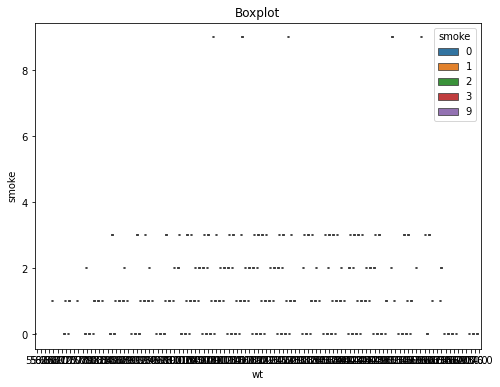

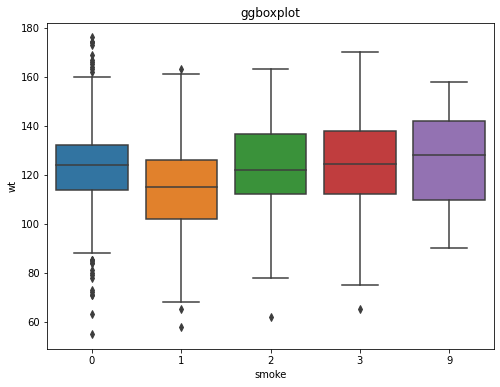

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, y='smoke', x='wt', hue='smoke')
plt.xlabel('wt')
plt.ylabel('smoke')
plt.legend(title='smoke')
plt.title('Boxplot')
plt.show()

# ggboxplot
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='smoke', y='wt')
plt.xlabel('smoke')
plt.ylabel('wt')
plt.title('ggboxplot')
plt.show()


In [65]:
import pandas as pd

# Assuming you have the data stored in a DataFrame called 'df'
# and 'wt' represents the weight variable, and 'smoke' represents the smoking status

# Group the data by 'smoke' variable
grouped_data = df.groupby('smoke')['wt']

# Calculate summary statistics for each group
summary_stats = grouped_data.describe()

# Print the statistical results
print(summary_stats)

       count        mean        std   min     25%    50%     75%    max
smoke                                                                  
0      540.0  122.861111  17.060222  55.0  113.75  124.0  132.25  176.0
1      481.0  114.108108  17.972686  58.0  102.00  115.0  126.00  163.0
2       95.0  123.084211  17.803695  62.0  112.00  122.0  136.50  163.0
3      100.0  124.630000  18.570453  65.0  112.00  124.5  138.00  170.0
9       10.0  126.700000  21.812586  90.0  109.75  128.0  141.75  158.0
